In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import square, sawtooth
import sounddevice as sd
from scipy.io.wavfile import write

from pathlib import Path
import pandas as pd 

In [2]:
FS = 44100

DURATION = 1.0

BASE_FREQ = 80

TARGET_RMS = 0.2

In [3]:
def rms_normalize(signal, target_rms=TARGET_RMS):

    rms = np.sqrt(np.mean(signal**2))

    if rms > 0:
        signal = signal * (target_rms / rms)

    return signal

In [4]:
def play(signal):

    signal = signal / np.max(np.abs(signal))

    sd.play(signal, FS)

    sd.wait()

In [5]:
def generate_component(
    frequency,
    waveform="sine",
    duration=DURATION
):

    t = np.linspace(
        0,
        duration,
        int(FS*duration),
        endpoint=False
    )

    if waveform == "sine":

        signal = np.sin(
            2*np.pi*frequency*t
        )

    elif waveform == "square":

        signal = square(
            2*np.pi*frequency*t
        )

    elif waveform == "saw":

        signal = sawtooth(
            2*np.pi*frequency*t
        )

    else:

        raise ValueError("Unknown waveform.")

    return signal

In [6]:
def generate_complex_vibration(

    waveform="sine",

    ifi=100,

    duration=DURATION,

    base_freq=BASE_FREQ

):

    freqs = []

    signal = np.zeros(
        int(FS*duration)
    )

    for i in range(3):

        freq = base_freq + i*ifi

        freqs.append(freq)

        signal += generate_component(
            freq,
            waveform,
            duration
        )

    signal = rms_normalize(signal)

    return signal, freqs

In [7]:
def apply_am(

    signal,

    depth,

    am_freq=10

):

    t = np.linspace(
        0,
        len(signal)/FS,
        len(signal),
        endpoint=False
    )

    envelope = (
        1
        +
        depth *
        np.sin(
            2*np.pi*am_freq*t
        )
    )

    output = signal * envelope

    output = rms_normalize(output)

    return output

In [8]:
waveforms = [

    "sine",

    "square",

    "saw"

]

In [9]:
for w in waveforms:

    print(w)

    signal, freqs = generate_complex_vibration(

        waveform=w,

        ifi=100

    )

    signal = apply_am(

        signal,

        depth=0.6

    )

    play(signal)

sine
square
saw


In [10]:
def save_wav(signal, filename):

    signal = signal / np.max(np.abs(signal))

    write(

        filename,

        FS,

        np.int16(signal * 32767)

    )

In [11]:
from pathlib import Path

output_dir = Path("../stimuli/waveform_27")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [12]:
waveforms = [
    "sine",
    "square",
    "saw"
]

ifis = [
    50,
    100,
    150
]

am_depths = [
    0.3,
    0.6,
    0.9
]

In [13]:
stimulus_table = []

stim_id = 1

for waveform in waveforms:

    for ifi in ifis:

        for am in am_depths:

            signal, freqs = generate_complex_vibration(

                waveform=waveform,
                ifi=ifi

            )

            signal = apply_am(

                signal,
                depth=am

            )

            filename = (

                f"S{stim_id:02d}"
                f"_{waveform}"
                f"_IFI{ifi}"
                f"_AM{int(am*100)}.wav"

            )

            save_wav(

                signal,
                output_dir / filename

            )

            stimulus_table.append(

                [

                    stim_id,
                    waveform,
                    ifi,
                    freqs,
                    am

                ]

            )

            stim_id += 1

In [14]:
df = pd.DataFrame(

    stimulus_table,

    columns=[

        "ID",
        "Waveform",
        "IFI",
        "Frequencies",
        "AM"

    ]

)

df

,ID,Waveform,IFI,Frequencies,AM
0,1,sine,50,"[80, 130, 180]",0.3
1,2,sine,50,"[80, 130, 180]",0.6
2,3,sine,50,"[80, 130, 180]",0.9
3,4,sine,100,"[80, 180, 280]",0.3
4,5,sine,100,"[80, 180, 280]",0.6
5,6,sine,100,"[80, 180, 280]",0.9
6,7,sine,150,"[80, 230, 380]",0.3
7,8,sine,150,"[80, 230, 380]",0.6
8,9,sine,150,"[80, 230, 380]",0.9
9,10,square,50,"[80, 130, 180]",0.3


In [15]:
df.to_csv(

    output_dir / "stimulus_waveform_table.csv",

    index=False

)

In [16]:
files = list(output_dir.glob("*.wav"))

print("Number of wav files:", len(files))

for f in files[:5]:

    print(f.name)

Number of wav files: 27
S01_sine_IFI50_AM30.wav
S02_sine_IFI50_AM60.wav
S03_sine_IFI50_AM90.wav
S04_sine_IFI100_AM30.wav
S05_sine_IFI100_AM60.wav


In [17]:
import random

for _ in range(10):

    idx = random.randint(1,27)

    row = df.iloc[idx-1]

    print(row)

    filename = (

        output_dir /

        f"S{idx:02d}"

        f"_{row.Waveform}"

        f"_IFI{row.IFI}"

        f"_AM{int(row.AM*100)}.wav"

    )

    from scipy.io.wavfile import read

    fs, signal = read(filename)

    signal = signal.astype(float)/32767

    play(signal)

ID                         11
Waveform               square
IFI                        50
Frequencies    [80, 130, 180]
AM                        0.6
Name: 10, dtype: object
ID                         12
Waveform               square
IFI                        50
Frequencies    [80, 130, 180]
AM                        0.9
Name: 11, dtype: object
ID                          4
Waveform                 sine
IFI                       100
Frequencies    [80, 180, 280]
AM                        0.3
Name: 3, dtype: object
ID                         15
Waveform               square
IFI                       100
Frequencies    [80, 180, 280]
AM                        0.9
Name: 14, dtype: object
ID                         13
Waveform               square
IFI                       100
Frequencies    [80, 180, 280]
AM                        0.3
Name: 12, dtype: object
ID                          2
Waveform                 sine
IFI                        50
Frequencies    [80, 130, 180]
AM         

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import square, sawtooth

FS = 44100
DURATION = 0.05      # only 50 ms so we can actually see it

t = np.linspace(
    0,
    DURATION,
    int(FS*DURATION),
    endpoint=False
)

freq = 80

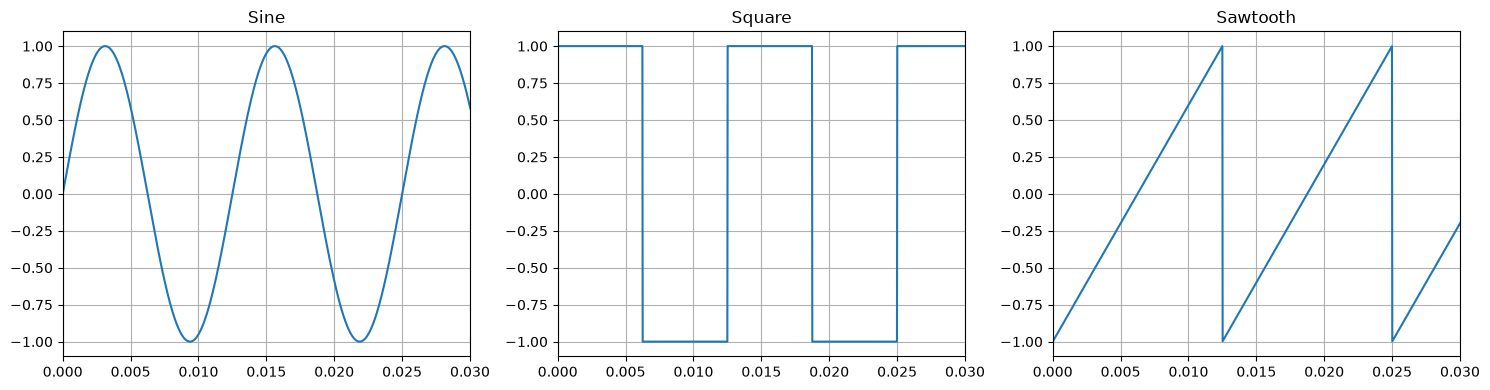

In [19]:
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)

plt.plot(
    t,
    np.sin(2*np.pi*freq*t)
)

plt.title("Sine")

plt.xlim(0,0.03)

plt.grid()


plt.subplot(1,3,2)

plt.plot(
    t,
    square(2*np.pi*freq*t)
)

plt.title("Square")

plt.xlim(0,0.03)

plt.grid()


plt.subplot(1,3,3)

plt.plot(
    t,
    sawtooth(2*np.pi*freq*t)
)

plt.title("Sawtooth")

plt.xlim(0,0.03)

plt.grid()

plt.tight_layout()

plt.show()

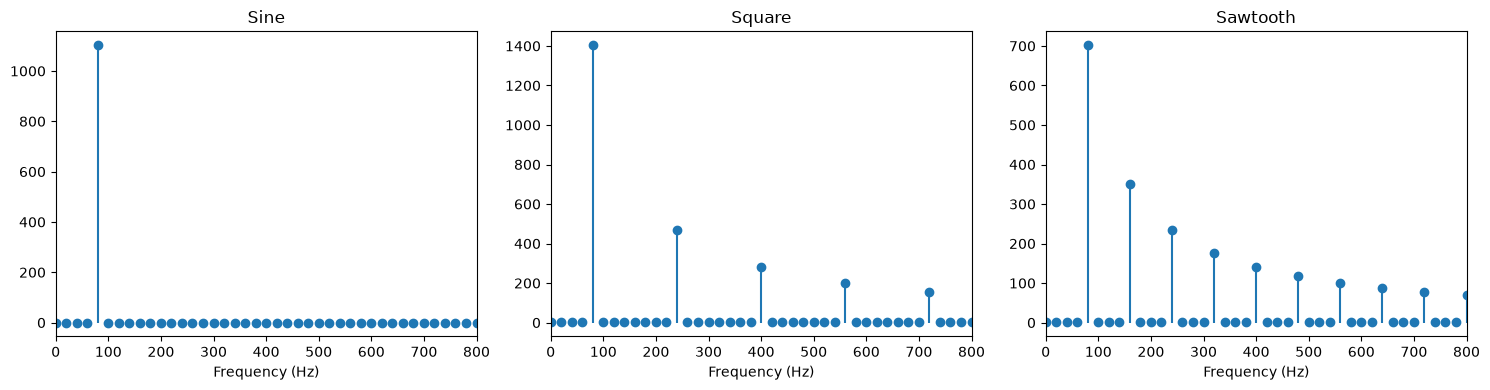

In [20]:
from scipy.fft import fft, fftfreq

waveforms = {
    "Sine": np.sin(2*np.pi*freq*t),
    "Square": square(2*np.pi*freq*t),
    "Sawtooth": sawtooth(2*np.pi*freq*t)
}

plt.figure(figsize=(15,4))

for i, (name, signal) in enumerate(waveforms.items()):

    yf = np.abs(fft(signal))

    xf = fftfreq(len(signal),1/FS)

    plt.subplot(1,3,i+1)

    plt.stem(
        xf[:600],
        yf[:600],
        basefmt=" "
    )

    plt.title(name)

    plt.xlim(0,800)

    plt.xlabel("Frequency (Hz)")

plt.tight_layout()

plt.show()

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

In [22]:
def plot_fft(signal, title):

    N = len(signal)

    yf = fft(signal)

    xf = fftfreq(N, 1/FS)

    magnitude = np.abs(yf)

    positive = xf >= 0

    plt.figure(figsize=(10,4))

    plt.stem(
        xf[positive],
        magnitude[positive],
        basefmt=" "
    )

    plt.xlim(0,1000)

    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.title(title)

    plt.grid(True)

    plt.show()

In [23]:
sine_signal, _ = generate_complex_vibration(
    waveform="sine",
    ifi=100
)

square_signal, _ = generate_complex_vibration(
    waveform="square",
    ifi=100
)

saw_signal, _ = generate_complex_vibration(
    waveform="saw",
    ifi=100
)

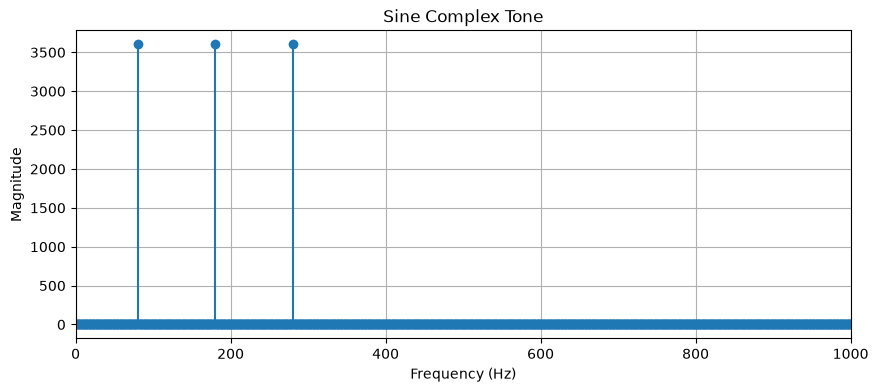

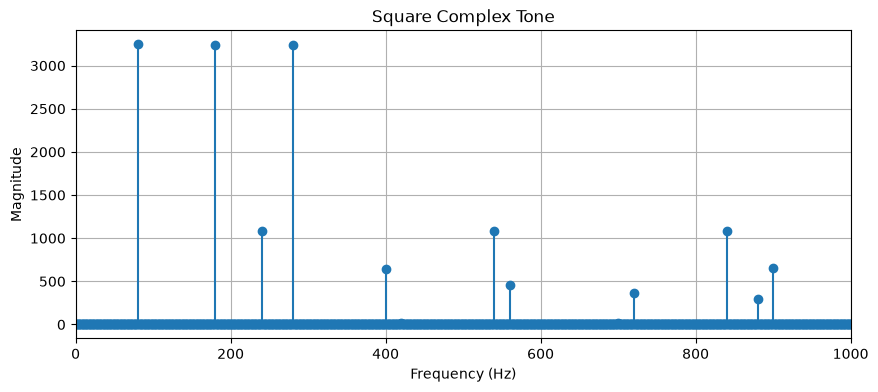

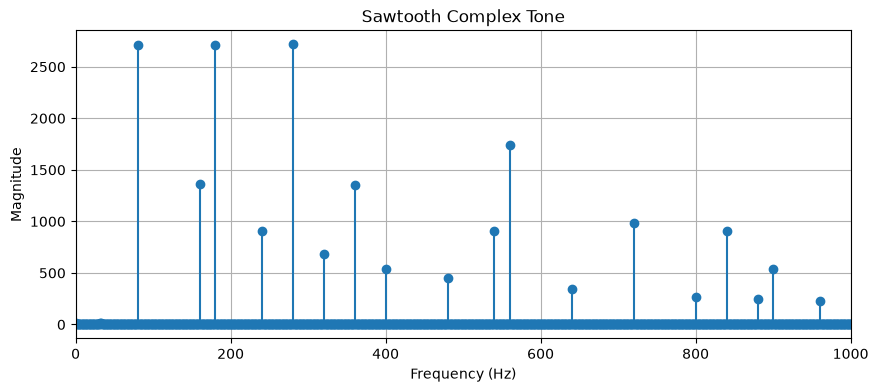

In [24]:
plot_fft(
    sine_signal,
    "Sine Complex Tone"
)

plot_fft(
    square_signal,
    "Square Complex Tone"
)

plot_fft(
    saw_signal,
    "Sawtooth Complex Tone"
)

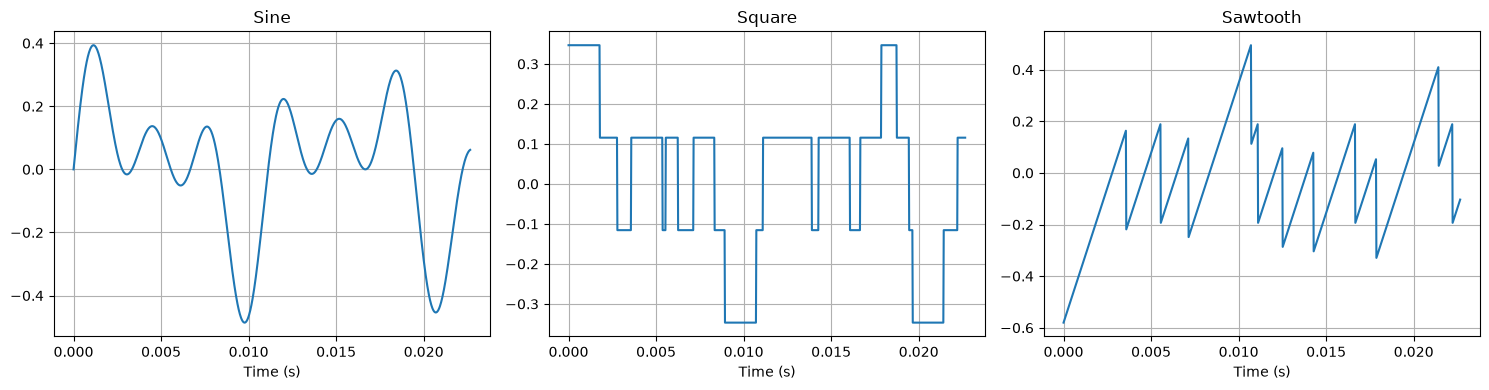

In [25]:
plt.figure(figsize=(15,4))

signals = [
    ("Sine", sine_signal),
    ("Square", square_signal),
    ("Sawtooth", saw_signal)
]

for i, (name, sig) in enumerate(signals):

    plt.subplot(1,3,i+1)

    plt.plot(
        np.arange(1000)/FS,
        sig[:1000]
    )

    plt.title(name)

    plt.xlabel("Time (s)")

    plt.grid(True)

plt.tight_layout()

plt.show()

In [26]:
from scipy.fft import fft, fftfreq

def get_fft(signal):

    N = len(signal)

    yf = np.abs(fft(signal))

    xf = fftfreq(N, 1/FS)

    positive = xf >= 0

    return xf[positive], yf[positive]

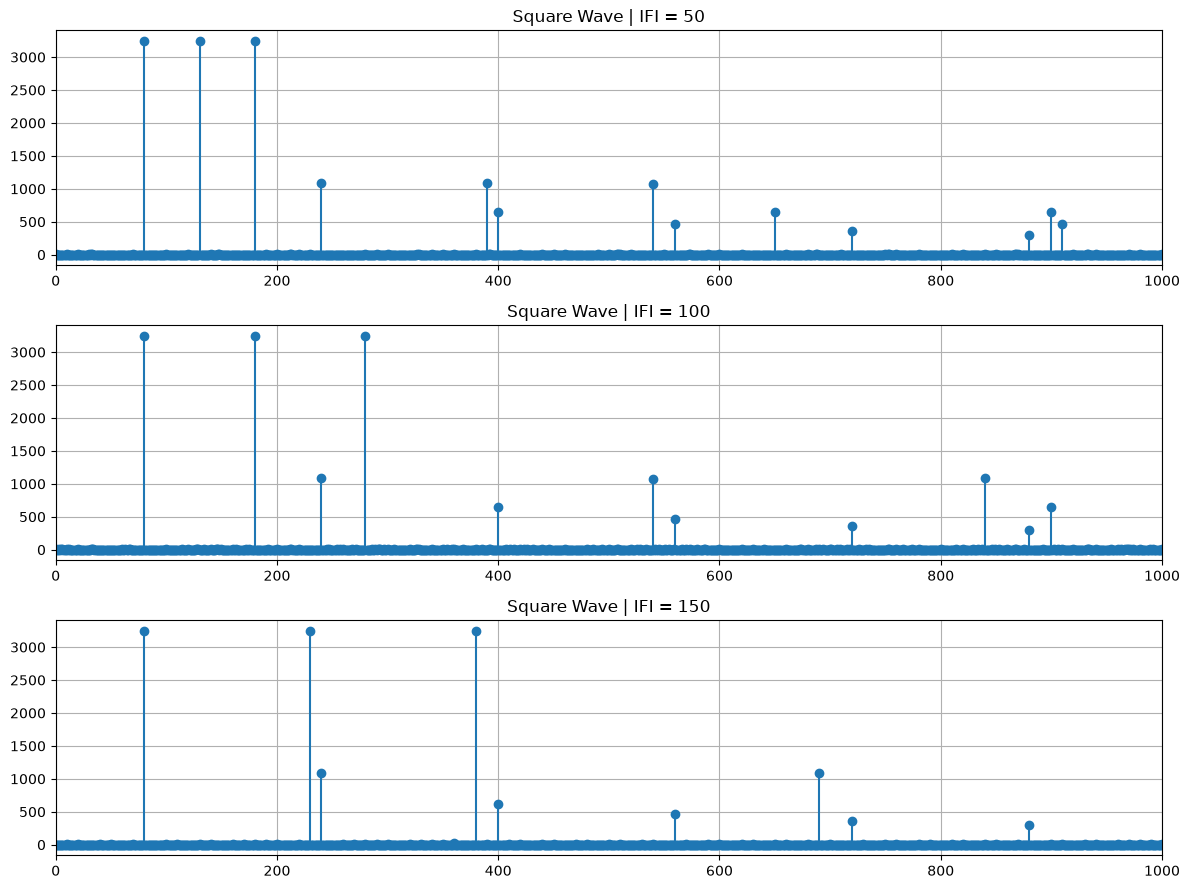

In [27]:
fig, axes = plt.subplots(3,1,figsize=(12,9))

for ax, ifi in zip(axes,[50,100,150]):

    signal,_ = generate_complex_vibration(
        waveform="square",
        ifi=ifi
    )

    xf,yf = get_fft(signal)

    ax.stem(
        xf,
        yf,
        basefmt=" "
    )

    ax.set_xlim(0,1000)

    ax.set_title(f"Square Wave | IFI = {ifi}")

    ax.grid(True)

plt.tight_layout()

plt.show()

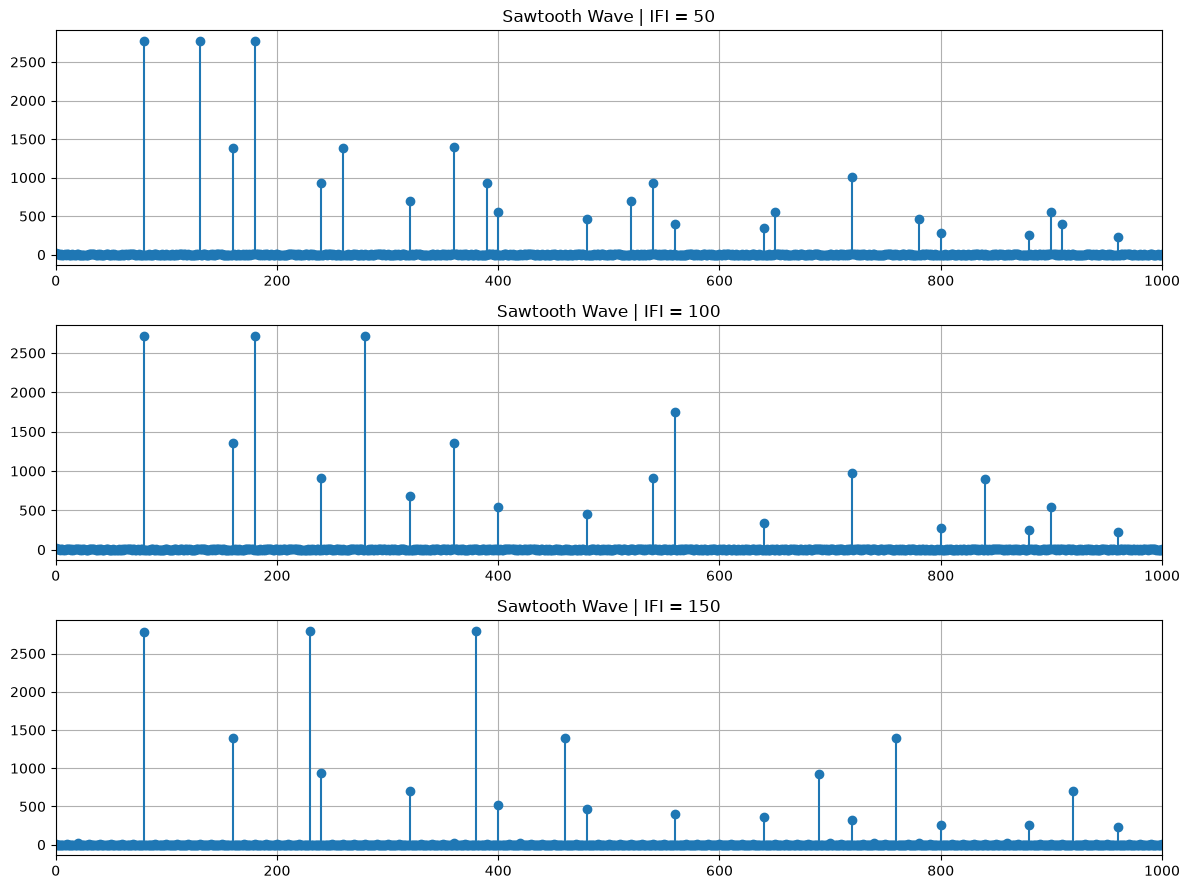

In [28]:
fig, axes = plt.subplots(3,1,figsize=(12,9))

for ax, ifi in zip(axes,[50,100,150]):

    signal,_ = generate_complex_vibration(
        waveform="saw",
        ifi=ifi
    )

    xf,yf = get_fft(signal)

    ax.stem(
        xf,
        yf,
        basefmt=" "
    )

    ax.set_xlim(0,1000)

    ax.set_title(f"Sawtooth Wave | IFI = {ifi}")

    ax.grid(True)

plt.tight_layout()

plt.show()